# BikeNodePlanner–dk_bicycle_network LTS combination
- Edges come from `dk_bicycle_network/data/processed/osm_road_edges.parquet` 
- Instead of taking the single OSM edge with the longest overlap, points are sampled every `SEGMENT_LENGTH_M` along each bike-loop link. Each point gets the **lowest** LTS within `TOLERANCE_M`, with a separate cycle track beating the road next to it. The link then gets `max_lts`, worst point, and the share of points in each LTS class.

## Setup

In [5]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
from IPython.display import display
from shapely.geometry import box

working_dir = Path.cwd().resolve()

PROJECT_ROOT = working_dir.parent if working_dir.name == "combine" else working_dir  # this notebook lives in bike_safety/combine/

# Output folders for this notebook
COMBINE_DIR = PROJECT_ROOT / "combine"
DATA_OUTPUT_DIR = COMBINE_DIR / "data"
PLOTS_OUTPUT_DIR = COMBINE_DIR / "plots"

# DK_bicycle_network with LTS, produced by dk_bicycle_network (script 11)
DK_NETWORK_EDGES_PATH = PROJECT_ROOT / "dk_bicycle_network/data/processed/osm_road_edges.parquet"

EXTRACTION_MARGIN_M = 500  # only needs to exceed TOLERANCE_M
TOLERANCE_M = 20           # max distance between a bike-loop link and an OSM edge
SEGMENT_LENGTH_M = 20      # distance between sample points along each bike-loop link

# Columns needed from the dk_bicycle_network edges
OSM_COLUMNS = [ "lts", "cycling_allowed", "geometry"]

# LTS 999 = no cycling (pedestrian paths). LTS 0 = car-free paths where cycling is allowed.
EXCLUDED_LTS = [999]
LTS_0_AS = 1  # research choice: treat car-free paths as low stress

## Load dk_bicycle_network edges (once for all of Denmark)

In [6]:
### Time: ≈ 1 min
dk_edges_dk = gpd.read_parquet(DK_NETWORK_EDGES_PATH, columns=OSM_COLUMNS)

dk_edges_dk = dk_edges_dk.loc[
    dk_edges_dk["cycling_allowed"] & ~dk_edges_dk["lts"].isin(EXCLUDED_LTS)
].copy()
dk_edges_dk["lts"] = dk_edges_dk["lts"].replace(0, LTS_0_AS)

print(f"dk_bicycle_network edges with cycling allowed: {len(dk_edges_dk):,}")
print("CRS:", dk_edges_dk.crs.to_string())
display(dk_edges_dk["lts"].value_counts().sort_index().to_frame("edges"))

dk_bicycle_network edges with cycling allowed: 1,958,633
CRS: EPSG:25832


,edges
lts,
1,679073
2,943144
3,216053
4,120363


# Denmark

In [7]:
SAMPLE = "denmark"

BIKE_LOOPS_DIR = PROJECT_ROOT / f"bikenwloops/data/input/{SAMPLE}/network/processed"
DATA_DIR = DATA_OUTPUT_DIR / SAMPLE
PLOTS_DIR = PLOTS_OUTPUT_DIR / SAMPLE
OUTPUT_PATH = DATA_DIR / "edges_slope_lts.gpkg"

DATA_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

print("Bike loop network directory:", BIKE_LOOPS_DIR)
print("Data output folder:", DATA_DIR)
print("Plots output folder:", PLOTS_DIR)

Bike loop network directory: /Users/astridarhnung/GitHub/bike_safety/bikenwloops/data/input/denmark/network/processed
Data output folder: /Users/astridarhnung/GitHub/bike_safety/combine/data/denmark
Plots output folder: /Users/astridarhnung/GitHub/bike_safety/combine/plots/denmark


In [8]:
# Load bike loop network data
bike_loops_edges = gpd.read_file(BIKE_LOOPS_DIR / "edges.gpkg")

bike_loops_edges = bike_loops_edges.loc[
    bike_loops_edges.geometry.notna()
    & ~bike_loops_edges.geometry.is_empty
].copy()

if bike_loops_edges.crs != dk_edges_dk.crs:
    raise ValueError("Bike-loop edges and dk_bicycle_network edges have different CRS.")

print(f"Bike loop edges: {len(bike_loops_edges):,}")

Bike loop edges: 12,216


### Extract area of interest from dk_bicycle_network

In [9]:
minx, miny, maxx, maxy = bike_loops_edges.total_bounds

dk_edges = dk_edges_dk.cx[
    minx - EXTRACTION_MARGIN_M : maxx + EXTRACTION_MARGIN_M,
    miny - EXTRACTION_MARGIN_M : maxy + EXTRACTION_MARGIN_M,
].copy()

print(f"dk_bicycle_network edges in {SAMPLE}: {len(dk_edges):,}")

dk_bicycle_network edges in denmark: 1,958,633


### Match LTS onto the bike-loop links

In [10]:
dk_spatial_index = dk_edges.sindex
dk_geometries = dk_edges.geometry.to_numpy()
dk_lts = dk_edges["lts"].to_numpy()

max_lts_values, coverage_pcts, lts_shares = [], [], []
number_of_edges = len(bike_loops_edges)

for position, geometry in enumerate(bike_loops_edges.geometry, start=1):

    # Sample points along the link, every SEGMENT_LENGTH_M
    distances = np.arange(0, geometry.length, SEGMENT_LENGTH_M)
    points = shapely.line_interpolate_point(geometry, distances)

    # Find only OSM lines within the matching tolerance
    candidate_positions = dk_spatial_index.query(
        geometry,
        predicate="dwithin",
        distance=TOLERANCE_M,
    )
    candidate_positions = np.unique(candidate_positions)

    # Lowest LTS within TOLERANCE_M of each point (inf = no match)
    point_lts = np.full(len(points), np.inf)
    if len(candidate_positions) > 0:
        candidate_geometries = dk_geometries[candidate_positions]
        is_near = shapely.dwithin(candidate_geometries[:, None], points[None, :], TOLERANCE_M)
        candidate_lts = dk_lts[candidate_positions].astype(float)
        point_lts = np.where(is_near, candidate_lts[:, None], np.inf).min(axis=0)

    matched_lts = point_lts[np.isfinite(point_lts)]

    max_lts_values.append(matched_lts.max() if len(matched_lts) else np.nan)
    coverage_pcts.append(100 * len(matched_lts) / len(points))
    lts_shares.append([100 * np.mean(point_lts == lts) for lts in (1, 2, 3, 4)])

    if position % 500 == 0:
        print(f"Processed {position:,} of {number_of_edges:,} bike-loop edges")

print("Matching completed.")

Processed 500 of 12,216 bike-loop edges
Processed 1,000 of 12,216 bike-loop edges
Processed 1,500 of 12,216 bike-loop edges
Processed 2,000 of 12,216 bike-loop edges
Processed 2,500 of 12,216 bike-loop edges
Processed 3,000 of 12,216 bike-loop edges
Processed 3,500 of 12,216 bike-loop edges
Processed 4,000 of 12,216 bike-loop edges
Processed 4,500 of 12,216 bike-loop edges
Processed 5,000 of 12,216 bike-loop edges
Processed 5,500 of 12,216 bike-loop edges
Processed 6,000 of 12,216 bike-loop edges
Processed 6,500 of 12,216 bike-loop edges
Processed 7,000 of 12,216 bike-loop edges
Processed 7,500 of 12,216 bike-loop edges
Processed 8,000 of 12,216 bike-loop edges
Processed 8,500 of 12,216 bike-loop edges
Processed 9,000 of 12,216 bike-loop edges
Processed 9,500 of 12,216 bike-loop edges
Processed 10,000 of 12,216 bike-loop edges
Processed 10,500 of 12,216 bike-loop edges
Processed 11,000 of 12,216 bike-loop edges
Processed 11,500 of 12,216 bike-loop edges
Processed 12,000 of 12,216 bike-

In [11]:
bike_loops_lts = bike_loops_edges.copy()
bike_loops_lts["max_lts"] = max_lts_values
bike_loops_lts["coverage_pct"] = coverage_pcts
bike_loops_lts[["lts1_pct", "lts2_pct", "lts3_pct", "lts4_pct"]] = lts_shares

display(bike_loops_lts[["edge_id", "mm_len", "max_lts", "coverage_pct", "lts1_pct", "lts2_pct", "lts3_pct", "lts4_pct"]].describe().round(1))
display(bike_loops_lts["max_lts"].value_counts(dropna=False).sort_index().to_frame("links"))

,edge_id,mm_len,max_lts,coverage_pct,lts1_pct,lts2_pct,lts3_pct,lts4_pct
count,12216.0,12216.0,12206.0,12216.0,12216.0,12216.0,12216.0,12216.0
mean,2533.7,2406.8,3.0,98.5,30.4,13.8,30.3,23.9
std,2134.1,1945.7,1.0,8.2,37.8,21.3,34.7,34.5
min,0.0,2.1,1.0,0.0,0.0,0.0,0.0,0.0
25%,708.0,967.3,3.0,100.0,1.9,0.0,0.0,0.0
50%,1866.5,2025.9,3.0,100.0,8.1,5.3,12.6,0.0
75%,4198.2,3366.3,4.0,100.0,59.2,16.7,60.4,51.7
max,7252.0,22218.6,4.0,100.0,100.0,100.0,100.0,100.0


,links
max_lts,
1.0,1763
2.0,1171
3.0,4147
4.0,5125
NaN,10


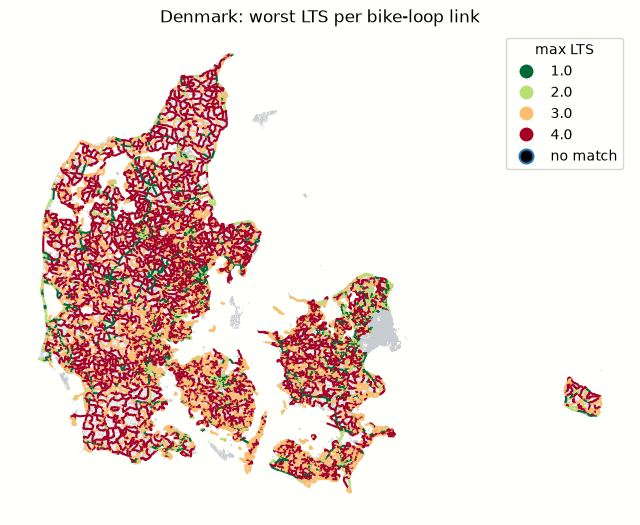

In [12]:
fig, ax = plt.subplots(figsize=(8, 8), facecolor="#fffffb")

dk_edges.plot(ax=ax, color="#c8cdd2", linewidth=0.3, alpha=0.6, zorder=1)
bike_loops_lts.plot(
    ax=ax,
    column="max_lts",
    categorical=True,
    cmap="RdYlGn_r",
    linewidth=1.5,
    legend=True,
    legend_kwds={"title": "max LTS"},
    missing_kwds={"color": "black", "label": "no match"},
    zorder=2,
)
ax.set_title(f"{SAMPLE.title()}: worst LTS per bike-loop link")
ax.set_axis_off()
fig.savefig(PLOTS_DIR / f"{SAMPLE}_max_lts.png", dpi=300, bbox_inches="tight")
plt.show()

In [13]:
bike_loops_lts.to_file(OUTPUT_PATH, driver="GPKG")
print("Saved:", OUTPUT_PATH)

Saved: /Users/astridarhnung/GitHub/bike_safety/combine/data/denmark/edges_slope_lts.gpkg
